# Session 2 – Building DDPG from Scratch for PMSM Current Control

In Session 1 we used a ready-made DDPG agent from Stable-Baselines3. In this session you **build every part yourself**
in PyTorch, train it on the PMSM, and study what happens when the current measurements are **noisy**.

### Learning goals
After this session you should be able to:
1. Implement the Actor and Critic networks in PyTorch and explain their inputs and outputs.
2. Implement a replay buffer and explain why it is needed.
3. Explain the role of exploration noise and target networks.
4. Implement the DDPG learning step: critic loss, actor loss and soft update.
5. Evaluate the effect of measurement noise and the use of transfer learning.

### Roadmap
| Part | Content |
|---|---|
| 1 | Environment with and without measurement noise |
| 2 | Actor network |
| 3 | Critic network |
| 4 | Replay buffer |
| 5 | Exploration noise |
| 6 | Hyperparameters |
| 7 | The DDPG agent: learning step |
| 8 | Training |
| 9 | Testing and comparison with PI |
| 10 | Transfer learning |

<div style="text-align: center">
  <img src="./images/Control_problem_DDPG.png" alt="DDPG control problem" />
</div>

In [1]:
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import pandas as pd
import matplotlib.pyplot as plt
import random
from collections import deque
import gymnasium as gym
import ipywidgets as widgets
from IPython.display import display, clear_output

from controllers import PIController
from environment import EnvPMSM
from utils import *          # Metrics, Logger, run_simulation, columns, ...
import warnings
warnings.filterwarnings('ignore')

%matplotlib inline

# Register gym environment
gym.register(
    id="EnvPMSM",
    entry_point=EnvPMSM,
)

figsize = (10, 6)

---
# 1. Environment

We use the same Gymnasium environment as in Session 1:

| Method | What it does |
|---|---|
| `__init__` | Parameters, discrete model $x_{k+1} = A_dx_k + B_du_k + w_d$, action and observation spaces |
| `reset()` | Currents back to $0$, returns the first observation |
| `step(action)` | Applies one voltage for $\Delta t$, returns `(observation, reward, terminated, truncated, info)` |

Quick reminder of the RL view of the problem:
- **Observation** $s_t = [I_d, I_q] / I_{\max}$ (normalised currents)
- **Action** $a_t = [V_d, V_q] / (V_{DC}/2) \in [-1, 1]^2$ (normalised voltages)
- **Reward** $r_t = -\left(|I_d - I_{d,\mathrm{ref}}| + |I_q - I_{q,\mathrm{ref}}|\right)/I_{\max}$

The sampling frequency is $10$ kHz, an episode lasts $200$ steps, the current is limited to $200$ A, the DC-bus voltage is
$1200$ V and the voltage is limited to $V_{DC}/2 = 600$ V.

In [2]:
sys_params = {
    "dt": 1 / 10e3,             # Simulation step time [s]
    "r": 29.0808e-3,            # Phase Stator Resistance [Ohm]
    "ld": 0.91e-3,              # D-axis Inductance [H]
    "lq": 1.17e-3,              # Q-axis Inductance [H]
    "lambda_PM": 0.172312604,   # Flux-linkage due to permanent magnets [Wb]
    "we": 50*2*np.pi,           # Electrical speed [rad/s]
    "vdc": 1200,                # DC bus voltage [V]
    "sim_steps": 200,           # Simulation steps per episode
    "i_max": 200,               # Maximum current [A]
    "id_ref": -10.0,            # Reference d-axis current [A]
    "iq_ref": 100.0             # Reference q-axis current [A]
}
sim_plot_steps = 20             # Number of steps shown in the plots

### 1.1 Measurement noise
Real current sensors are noisy. With `meas_noise=True` the environment adds Gaussian noise to the **observations and the
reward**. The true currents are not affected. The noise level is set by a signal-to-noise ratio of $40$ dB:
$$
\sigma = 10^{-\mathrm{SNR}/20} = 10^{-2} = 0.01 \quad\text{(normalised)} \;\;\Rightarrow\;\; 0.01 \cdot 200\,\mathrm{A} = 2\,\mathrm{A}.
$$
We create two environments: one with perfect measurements, and one with noisy measurements.

In [3]:
env       = gym.make("EnvPMSM", sys_params=sys_params, meas_noise=False)
env_noisy = gym.make("EnvPMSM", sys_params=sys_params, meas_noise=True)
i_max = sys_params["i_max"]

Let's see what the agent "sees" in both cases. We apply the same constant voltage to both environments:

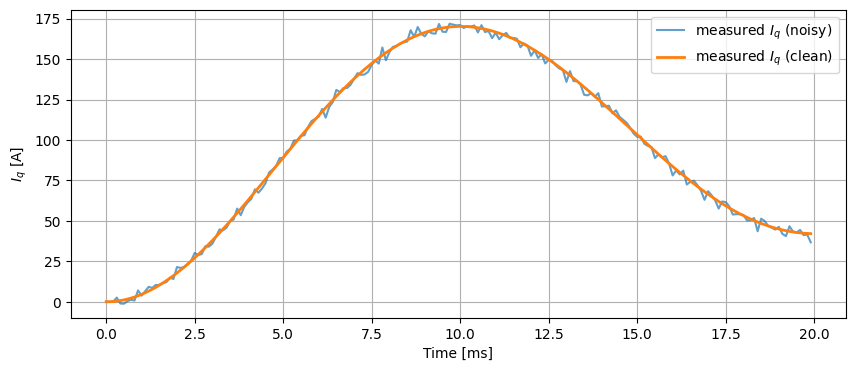

Std of the measurement noise: 2.14 A


In [4]:
action = np.array([-0.06, 0.09], dtype=np.float32)   # about [-37, 54] V
traces = {}
for name, e in [("clean", env), ("noisy", env_noisy)]:
    obs, _ = e.reset(seed=0)
    iq = [obs[1] * i_max]
    for _ in range(sys_params["sim_steps"] - 1):
        obs, *_ = e.step(action)
        iq.append(obs[1] * i_max)
    traces[name] = np.array(iq)

t_ms = 1e3 * sys_params["dt"] * np.arange(len(traces["clean"]))
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(t_ms, traces["noisy"], alpha=.7, label="measured $I_q$ (noisy)")
ax.plot(t_ms, traces["clean"], lw=2, label="measured $I_q$ (clean)")
ax.set_xlabel("Time [ms]"); ax.set_ylabel("$I_q$ [A]"); ax.grid(True); ax.legend()
plt.show()
print(f"Std of the measurement noise: {np.std(traces['noisy'] - traces['clean']):.2f} A")

**Question.** The reward is computed from the noisy measurement too. What does that mean for the learning signal the
agent receives? Would the same perfect controller get the same reward twice?

In [5]:
# Metrics from utils.py (same definitions as in Session 1)
metrics = Metrics(np.array([sys_params["id_ref"], sys_params["iq_ref"]]), sys_params["dt"])

---
# 2. The Actor network

The **Actor** is the controller: a neural network that maps a state to an action,
$$
a_t = \pi(s_t \,|\, \theta^\pi).
$$

- **Input:** the observation $s_t$, of size 2 ($I_d, I_q$)
- **Output:** the action $a_t$, of size 2 ($V_d, V_q$), which must stay within the action limits
- **Trained to:** output actions for which the Critic predicts a high value (Part 7)

<div style="text-align: center">
  <img src="./images/Actor_Network_1.png" alt="Actor Network" />
</div>

### Architecture
A multi-layer perceptron (MLP):
```
Linear(obs_dim → h1) → ReLU → Linear(h1 → h2) → ReLU → ... → Linear(h_last → act_dim) → Tanh
```
- **ReLU** hidden layers make the network non-linear.
- **Tanh** on the output squashes every value into $[-1, 1]$, so the actions can never exceed the limits.
- The output is then mapped to the action space $[a_{\mathrm{low}}, a_{\mathrm{high}}]$:
$$
a = \tanh(\cdot)\cdot\underbrace{\frac{a_{\mathrm{high}} - a_{\mathrm{low}}}{2}}_{\text{scale}} + \underbrace{\frac{a_{\mathrm{high}} + a_{\mathrm{low}}}{2}}_{\text{bias}}.
$$
Here the action space is already $[-1, 1]$, so scale $= 1$ and bias $= 0$, but this keeps the code general.

### PyTorch reminders
- A network is a class that inherits from `nn.Module`. Its layers are defined in `__init__` and used in `forward`.
- `nn.Sequential(*layers)` chains a list of layers.
- `register_buffer` stores a tensor that moves with the model (`.to(device)`) and is saved with it, but is **not** trained.
- Networks always work on **batches**: the input has shape `(batch_size, obs_dim)`.

`HIDDEN_SIZES` sets the width of each hidden layer. The pretrained weights in `weights/` were trained with the value below.
If you change it, you have to retrain.

In [6]:
HIDDEN_SIZES = (256, 256)   # Width of each hidden layer


class ActorNetwork(nn.Module):
    def __init__(self, observation_space, action_space, hidden_sizes=HIDDEN_SIZES):
        super().__init__()
        obs_dim = int(np.prod(observation_space.shape))
        act_dim = int(np.prod(action_space.shape))

        # Linear -> ReLU for every hidden layer, then Linear -> Tanh for the output
        layers = []
        in_size = obs_dim
        for h in hidden_sizes:
            layers += [nn.Linear(in_size, h), nn.ReLU()]
            in_size = h
        layers += [nn.Linear(in_size, act_dim), nn.Tanh()]
        self.network = nn.Sequential(*layers)

        # Map tanh output [-1, 1] to [low, high] of the action space
        self.register_buffer(
            "action_scale", torch.tensor((action_space.high - action_space.low) / 2, dtype=torch.float32)
        )
        self.register_buffer(
            "action_bias", torch.tensor((action_space.high + action_space.low) / 2, dtype=torch.float32)
        )

    def forward(self, observation):
        action = self.network(observation)
        return action * self.action_scale + self.action_bias

---
# 3. The Critic network

The **Critic** estimates how good it is to take action $a$ in state $s$, assuming the Actor's policy is followed afterwards:
$$
Q(s_t, a_t \,|\, \theta^Q) \approx \mathbb{E}\Big[\sum_{k=0}^{\infty}\gamma^k r_{t+k}\Big].
$$

- **Input:** the state **and** the action, concatenated into a vector of size $2 + 2 = 4$
- **Output:** a single number, the Q-value
- **Trained to:** satisfy the Bellman equation $Q(s_t,a_t) \approx r_t + \gamma\, Q(s_{t+1}, \pi(s_{t+1}))$ (Part 7)

The output layer has **no activation**: Q-values can be any real number. Here they are always negative, because every
reward is $\le 0$.

<div style="text-align: center">
  <img src="./images/Critic_Network_1.png" alt="Critic Network" />
</div>

**PyTorch tip.** `torch.cat([a, b], dim=1)` joins two tensors of shapes `(B, 2)` and `(B, 2)` into one of shape `(B, 4)`.

In [7]:
HIDDEN_SIZES = (256,256)   # Width of each hidden layer

class CriticNetwork(nn.Module):
    def __init__(self, observation_space, action_space, hidden_sizes=HIDDEN_SIZES):
        super().__init__()
        in_size = int(np.prod(observation_space.shape) + np.prod(action_space.shape))

        # Linear -> ReLU for every hidden layer, then a Linear output with ONE value (no activation)
        layers = []
        for h in hidden_sizes:
            layers += [nn.Linear(in_size, h), nn.ReLU()]
            in_size = h
        layers += [nn.Linear(in_size, 1)]
        self.network = nn.Sequential(*layers)

    def forward(self, observation, action):
        return self.network(torch.cat([observation, action], dim=1))

**Question.** Why does the Critic need the action as an input, while the Actor does not?

---
# 4. Replay buffer

The **replay buffer** is a memory of past experiences (transitions):
$$
(s_t,\; a_t,\; r_t,\; s_{t+1},\; d_t)
$$
where $d_t$ (*done*) is $1$ if the episode ended after this step.

**Why we need it**
- **Break correlations.** Consecutive steps are almost identical (the currents change slowly). Training a network on them
  in order is like studying only one page of a book. Random samples are much more informative.
- **Reuse data.** Every experience can be used for many updates, instead of being thrown away after one.

**How it works**
1. After every environment step, the transition is stored with `push`.
2. When the buffer is full, the **oldest** transitions are removed. `collections.deque(maxlen=capacity)` does this automatically.
3. For every learning step, a random mini-batch is drawn with `sample`.

**Python tips**
- `random.sample(list_like, k)` picks `k` different elements at random.
- `zip(*batch)` turns a list of tuples `[(s1, a1, ...), (s2, a2, ...)]` into tuples per field `(s1, s2, ...), (a1, a2, ...)`.

### Exercise 3 – Implement the replay buffer

In [8]:
class ReplayBuffer:
    def __init__(self, capacity):
        self.buffer = deque(maxlen=capacity)   # oldest transitions are dropped automatically

    def push(self, transition):
        state, action, reward, next_state, terminated, truncated = transition
        done = terminated or truncated
        self.buffer.append((state, action, reward, next_state, done))

    def sample(self, batch_size):
        batch = random.sample(self.buffer, batch_size)
        observations, actions, rewards, next_observations, terminations = zip(*batch)
        return observations, actions, rewards, next_observations, terminations

    def __len__(self):
        return len(self.buffer)

**Question.** Look at the hyperparameters in Part 6: the buffer capacity equals the total number of training steps.
What does that mean? Would a much smaller buffer be better or worse?

---
# 5. Exploration noise: Ornstein–Uhlenbeck

The Actor is **deterministic**: for the same state it always gives the same action. To discover better actions the agent
has to try something different, so during training we add noise to the action:
$$
a_t' = \pi(s_t) + \mathcal{N}_t, \qquad a_t' \text{ clipped to the action limits.}
$$

A common choice in DDPG is **Ornstein–Uhlenbeck (OU) noise**. Unlike independent Gaussian noise, OU noise is **correlated in time**:
it wanders smoothly instead of jumping at every step. This suits physical systems with inertia, like motors.

**[Discrete-time update](https://www.quantstart.com/articles/ornstein-uhlenbeck-simulation-with-python/):**
$$
x_{t+1} = x_t + \theta (\mu - x_t) \Delta t + \sigma \sqrt{\Delta t} \, \mathcal{N}(0, 1)
$$

| Symbol | Meaning |
|---|---|
| $x_t$ | current noise value |
| $\mu$ | long-term mean (usually 0) |
| $\theta$ | how fast the noise is pulled back to $\mu$ |
| $\sigma$ | strength of the random kicks |
| $\Delta t$ | time step |

The noise is reset to $\mu$ at the start of every episode.

In [9]:
class OrnsteinUhlenbeckNoise:
    "OU noise generator, used to add temporally correlated noise to actions."
    def __init__(self, size: int, dt: float, mu=0.0, sigma=0.1, theta=0.15):
        self.dt = dt
        self.mu = mu * torch.ones(size)
        self.sigma = sigma
        self.theta = theta
        self.size = size
        self.reset()

    def reset(self):
        "Resets the noise to its mean."
        self.state = self.mu.clone()

    def sample(self):
        "Returns the next value of the process."
        dx = self.theta * (self.mu - self.state) * self.dt + self.sigma * np.sqrt(self.dt) * torch.randn(self.size)
        self.state += dx
        return self.state.clone()

Let's compare one episode of OU noise with independent Gaussian noise of the same $\sigma$, using two different time steps:

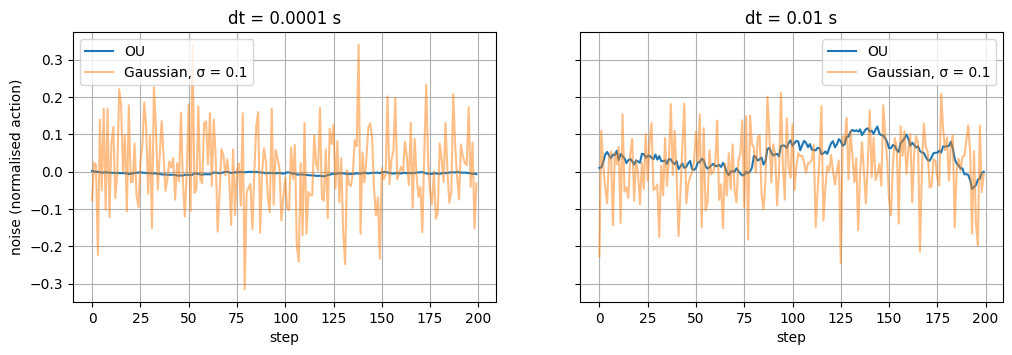

In [10]:
torch.manual_seed(0)
n = sys_params["sim_steps"]
fig, axes = plt.subplots(1, 2, figsize=(12, 3.5), sharey=True)
for ax, dt in zip(axes, [sys_params["dt"], 1e-2]):
    ou = OrnsteinUhlenbeckNoise(size=1, dt=dt, sigma=0.1, theta=0.15)
    ax.plot([ou.sample().item() for _ in range(n)], label="OU")
    ax.plot(0.1 * torch.randn(n).numpy(), alpha=.5, label="Gaussian, σ = 0.1")
    ax.set_title(f"dt = {dt:g} s"); ax.set_xlabel("step"); ax.grid(True); ax.legend()
axes[0].set_ylabel("noise (normalised action)")
plt.show()

---
# 6. Hyperparameters

All settings of the algorithm are collected in one configuration class:

| Parameter | Value | Meaning |
|---|---|---|
| `total_steps` | 50 000 | Number of environment steps (250 episodes × 200 steps) |
| `target_reward` | −0.1 | Stop early when the mean return of the last 20 episodes reaches this |
| `learning_starts` | 5 000 | Number of steps with **random** actions before learning starts, to fill the buffer |
| `gamma` | 0.99 | Discount factor $\gamma$: how much future rewards count |
| `lr` | 3·10⁻⁴ | Learning rate of the Adam optimisers |
| `buffer_capacity` | 50 000 | Maximum number of stored transitions |
| `batch_size` | 64 | Transitions per learning step |
| `tau` | 0.005 | Soft-update rate of the target networks |
| `noise_sigma`, `noise_theta` | 0.1, 0.15 | OU noise parameters |
| `print_every` | 1 | Refresh the training printout every this many episodes |

In [11]:
class DDPGConfig:
    env_name: str             =                   'EnvPMSM'  # Environment name
    agent_name: str           =                      'DDPG'  # Agent name
    verbose: bool             =                        True  # Print and plot training progress
    print_every: int          =                           1  # Refresh the printout every N episodes
    total_steps: int          = 250*sys_params["sim_steps"]  # Total training steps
    target_reward: float      =                        -0.1  # Mean return (last 20 episodes) for early stopping
    learning_starts: int      =                        5000  # Begin learning after this many steps
    gamma: float              =                        0.99  # Discount factor
    lr: float                 =                        3e-4  # Learning rate
    buffer_capacity: int      = 250*sys_params["sim_steps"]  # Maximum replay buffer capacity
    batch_size: int           =                          64  # Batch size used by learner
    tau: float                =                       0.005  # Soft target network update coefficient
    noise_sigma: float        =                         0.1  # OU noise standard deviation
    noise_theta: float        =                        0.15  # OU noise reversion rate

---
# 7. The DDPG agent

Now we put everything together. The agent owns **four** networks:

| Network | Symbol | Role |
|---|---|---|
| Actor | $\pi(s\,\vert\,\theta^\pi)$ | Chooses actions. This is the controller. |
| Critic | $Q(s,a\,\vert\,\theta^Q)$ | Rates actions |
| Target Actor | $\pi'(s\,\vert\,\theta^{\pi'})$ | Slowly moving copy of the Actor, used only to compute targets |
| Target Critic | $Q'(s,a\,\vert\,\theta^{Q'})$ | Slowly moving copy of the Critic, used only to compute targets |

### 7.1 Why target networks?
The Critic is trained to match a target that is computed **with the Critic itself**. If both change at every step, the
network is chasing its own tail and training can diverge. Target networks change slowly, so the target stays almost
fixed for a while.

### 7.2 The learning step
For a mini-batch of $N$ transitions $(s_i, a_i, r_i, s_{i+1}, d_i)$:

**1. Critic update.** Make $Q$ satisfy the Bellman equation:
$$
y_i = r_i + \gamma\,(1 - d_i)\; Q'\big(s_{i+1},\, \pi'(s_{i+1})\big), \qquad
L_Q = \frac{1}{N}\sum_i \big(Q(s_i,a_i) - y_i\big)^2
$$
- The factor $(1 - d_i)$ removes the future value when the episode has ended: there is no "next state" to look at.
- $y_i$ is a **fixed target**, so it is computed inside `torch.no_grad()` and gradients do not flow through it.

**2. Actor update.** Change the Actor so that the Critic rates its actions higher. We *maximise* $Q$, which is the same as
*minimising* $-Q$:
$$
L_\pi = -\frac{1}{N}\sum_i Q\big(s_i,\, \pi(s_i)\big)
$$
The gradient flows **through the Critic into the Actor**. Only the Actor's optimiser takes a step, so the Critic is not changed here.

**3. Soft update of the targets**, with $\tau \ll 1$:
$$
\theta' \leftarrow \tau\,\theta + (1-\tau)\,\theta'
$$
With $\tau = 1$ this is an exact copy, which is how the targets are initialised.

### 7.3 PyTorch training pattern
Every network update follows the same three lines:
```python
optimizer.zero_grad()   # clear old gradients
loss.backward()         # compute new gradients
optimizer.step()        # update the weights
```

### DDPG agent


In [12]:
class DDPG:
    def __init__(self, env, config=None):
        self.config = config if config is not None else DDPGConfig()
        self.device = "cuda" if torch.cuda.is_available() else "cpu"
        self.env = env

        observation_space, action_space = env.observation_space, env.action_space

        # Actor and Target Actor (the target starts as an exact copy: tau = 1)
        self.actor = ActorNetwork(observation_space, action_space).to(self.device)
        self.target_actor = ActorNetwork(observation_space, action_space).to(self.device)
        self.soft_update(self.actor, self.target_actor, 1.0)
        self.actor_optimizer = torch.optim.Adam(self.actor.parameters(), lr=self.config.lr)

        # Critic and Target Critic
        self.critic = CriticNetwork(observation_space, action_space).to(self.device)
        self.target_critic = CriticNetwork(observation_space, action_space).to(self.device)
        self.soft_update(self.critic, self.target_critic, 1.0)
        self.critic_optimizer = torch.optim.Adam(self.critic.parameters(), lr=self.config.lr)

        # Replay buffer
        self.buffer = ReplayBuffer(self.config.buffer_capacity)

        # Exploration noise
        self.noise_generator = OrnsteinUhlenbeckNoise(
            size=int(np.prod(action_space.shape)), dt=sys_params['dt'], mu=0.0,
            sigma=self.config.noise_sigma, theta=self.config.noise_theta
        )

    # ------------------------------------------------------------------
    def save_model(self, filename):
        "Save the weights of the actor and critic (online and target) networks."
        torch.save({
            'actor':         self.actor.state_dict(),
            'target_actor':  self.target_actor.state_dict(),
            'critic':        self.critic.state_dict(),
            'target_critic': self.target_critic.state_dict()
        }, f"weights/{filename}.pt")

    def load_model(self, filename):
        "Load the weights of the actor and critic (online and target) networks."
        weights = torch.load(f"weights/{filename}.pt", weights_only=True, map_location=self.device)
        self.actor.load_state_dict(weights["actor"])
        self.target_actor.load_state_dict(weights["target_actor"])
        self.critic.load_state_dict(weights["critic"])
        self.target_critic.load_state_dict(weights["target_critic"])

    # ------------------------------------------------------------------
    def soft_update(self, online, target, tau):
        "theta_target <- tau * theta_online + (1 - tau) * theta_target"
        with torch.no_grad():
            for online_param, target_param in zip(online.parameters(), target.parameters()):
                target_param.copy_(tau * online_param + (1.0 - tau) * target_param)

    def select_action(self, observation, add_noise=False):
        "One observation (NumPy) in, one action (NumPy) out. Optional exploration noise."
        with torch.no_grad():
            observation_tensor = torch.tensor(observation, dtype=torch.float32, device=self.device).unsqueeze(0)
            action = self.actor(observation_tensor).squeeze(0)          # (1, obs_dim) -> (act_dim,)
            if add_noise:
                noise = self.actor.action_scale * self.noise_generator.sample().to(self.device)
                action = torch.clamp(action + noise, min=-self.actor.action_scale, max=self.actor.action_scale)
            return action.cpu().numpy()

    # ------------------------------------------------------------------
    def learn(self):
        "Perform a single learning step on one mini-batch."
        B = self.config.batch_size

        # Sample a mini-batch and convert it to tensors of shape (B, dim)
        observations, actions, rewards, next_observations, terminations = self.buffer.sample(B)
        to_tensor = lambda x: torch.tensor(np.array(x), dtype=torch.float32, device=self.device).view(B, -1)
        observations, actions = to_tensor(observations), to_tensor(actions)
        rewards, next_observations = to_tensor(rewards), to_tensor(next_observations)
        terminations = to_tensor(terminations)

        # 1. Critic update: y = r + gamma * (1 - d) * Q'(s', pi'(s'))
        with torch.no_grad():
            next_state_q = self.target_critic(next_observations, self.target_actor(next_observations))
            target_q = rewards + self.config.gamma * (1.0 - terminations) * next_state_q
        current_q = self.critic(observations, actions)
        critic_loss = F.mse_loss(current_q, target_q)

        self.critic_optimizer.zero_grad()
        critic_loss.backward()
        self.critic_optimizer.step()

        # 2. Actor update: maximise Q(s, pi(s))  <=>  minimise -Q(s, pi(s))
        actor_loss = -self.critic(observations, self.actor(observations)).mean()

        self.actor_optimizer.zero_grad()
        actor_loss.backward()
        self.actor_optimizer.step()

        # 3. Soft update of both target networks
        self.soft_update(self.actor, self.target_actor, self.config.tau)
        self.soft_update(self.critic, self.target_critic, self.config.tau)

        return critic_loss.item(), actor_loss.item()

    # ------------------------------------------------------------------
    def train(self, filename):
        "Train the agent with the settings in self.config."
        cfg = self.config
        if cfg.verbose:
            print(f"Training {cfg.agent_name} agent...\n")

        logger = Logger(total_steps=cfg.total_steps)
        observation, _ = self.env.reset()
        n_episodes = 0

        for step in range(1, cfg.total_steps + 1):

            # 1. Select an action: random at first, then Actor + noise
            if step > cfg.learning_starts:
                action = self.select_action(observation, add_noise=True)
            else:
                action = self.env.action_space.sample()

            # 2. Interact with the environment
            next_observation, reward, terminated, truncated, _ = self.env.step(action)
            logger.log(reward, terminated, truncated)

            # 3. Store the transition
            self.buffer.push((observation, action, reward, next_observation, terminated, truncated))

            # 4. Learn from a random mini-batch
            if len(self.buffer) > cfg.batch_size and step >= cfg.learning_starts:
                self.learn()

            # 5. End of episode: reset environment and noise
            if terminated or truncated:
                next_observation, _ = self.env.reset()
                self.noise_generator.reset()
                n_episodes += 1

                # Refresh the printout once per `print_every` episodes (refreshing every step is very slow)
                if cfg.verbose and n_episodes % cfg.print_every == 0:
                    clear_output(wait=True)
                    logger.print_logs()
                    logger.plot_logs()

                # Early stopping
                if cfg.target_reward is not None and len(logger.episode_returns) >= 20:
                    if np.mean(logger.episode_returns[-20:]) >= cfg.target_reward:
                        if cfg.verbose:
                            print("\nTarget reward achieved. Training stopped.")
                        break
            observation = next_observation

        self.save_model(filename)
        if cfg.verbose:
            print("\nTraining complete.")
        return logger.logs

**Questions**
1. What would happen with `tau = 1` at every learning step? And with `tau = 0`?
2. The environment returns `terminated = True` at the last step of the episode, which is really a **time limit**. With
   the factor $(1-d_i)$, what does the Critic learn about the value of the last state? Would `truncated` be more correct here?

---
# 8. Training

Training requires some computing power, so precomputed weights are provided in the `weights` folder and training is
disabled during the session. Set `train = True` to train at home. Expect roughly 10–20 minutes per agent on a laptop CPU.

During training the logger shows the progress, the mean return per episode and the episode length. A **return** is the sum
of the rewards of one episode, so here the best possible return is $0$.

In [13]:
train = False

### 8.1 Training without measurement noise

In [14]:
ddpg = DDPG(env)
if train:
    ddpg_logs = ddpg.train("DDPG")

In [15]:
# Load the trained (or precomputed) weights
ddpg.load_model("DDPG")

### 8.2 Training with measurement noise
Exactly the same algorithm, but every observation and reward the agent receives is noisy.

In [16]:
ddpg_with_noise = DDPG(env_noisy)
if train:
    ddpg_with_noise_logs = ddpg_with_noise.train("DDPG_noise")

In [17]:
ddpg_with_noise.load_model("DDPG_noise")

---
# 9. Testing

We test both agents on **both** environments, without exploration noise. This gives four combinations:

| | Tested on clean env | Tested on noisy env |
|---|---|---|
| **Trained on clean env** | ✓ | robustness to unseen noise |
| **Trained on noisy env** | ✓ | ✓ |

DDPG trained WITHOUT measurement noise


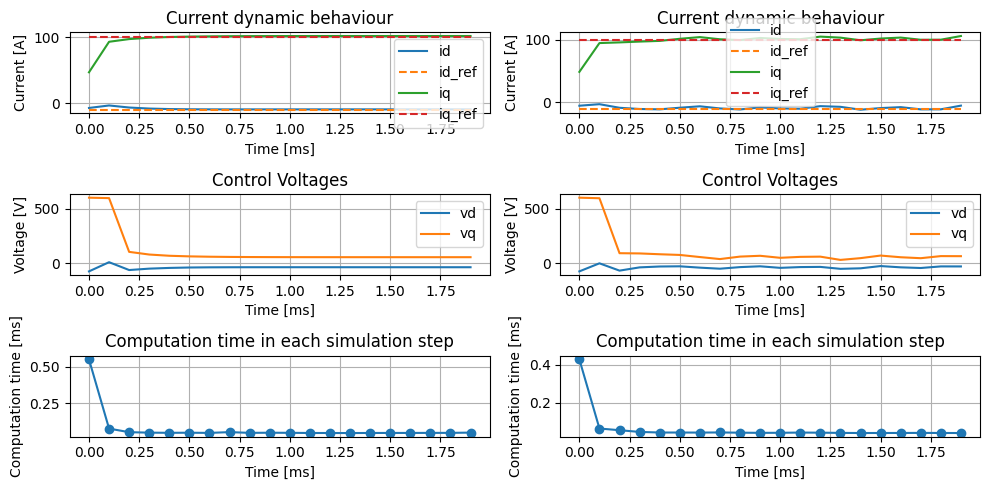

DDPG trained WITH measurement noise


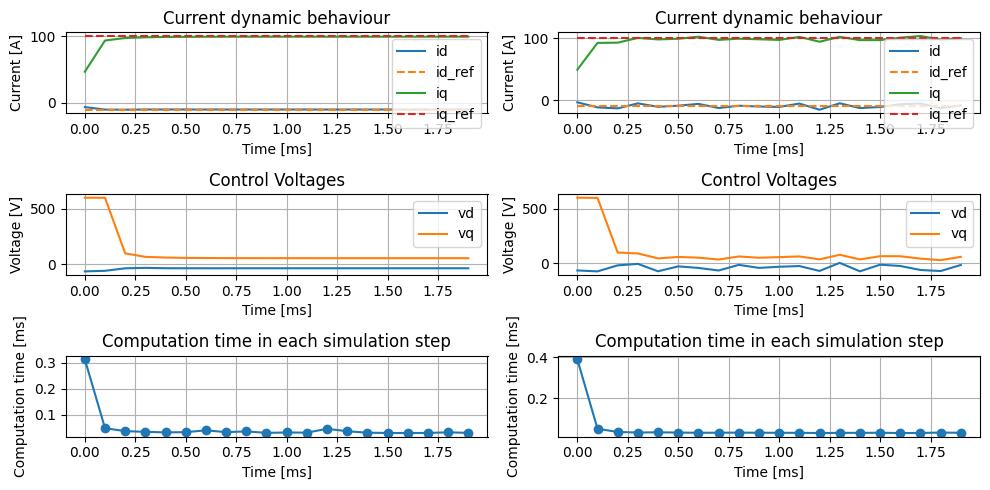

In [22]:
def show_table(table_data, index):
    "Display the metrics returned by run_simulation as a formatted table."
    table = pd.DataFrame(table_data, index=index, columns=columns).fillna("")
    table = table.style \
        .format(precision=3, thousands=".", decimal=",") \
        .set_table_styles([
            {"selector": "th", "props": [("text-align", "center")]},
            {"selector": "td", "props": [("text-align", "center")]}
        ])
    display(table)


def run_DDPG_controller_sim(envs, ddpg, index=("DDPG / env", "DDPG / noisy env"), figsize=(10, 5), show=True):
    table_data = run_simulation(envs=envs, controller=ddpg, controller_type="RL", metrics=metrics,
                                figsize=figsize, sim_steps=sim_plot_steps, plot=show)
    if show:
        show_table(table_data, list(index))
    return table_data


print("DDPG trained WITHOUT measurement noise")
_ = run_DDPG_controller_sim([env, env_noisy], ddpg)
print("DDPG trained WITH measurement noise")
_ = run_DDPG_controller_sim([env, env_noisy], ddpg_with_noise)

### 9.1 PI controller on the noisy environment
As a baseline, here is the PI controller from Session 1 on the noisy environment. Note that the noise enters the PI
controller **directly** through the proportional term $K_p\,e$.

In [19]:
def run_pi_controller_sim(Kp, Ki, envs, figsize=(10, 5), show=True):
    controller = PIController(Kp=Kp, Ki=Ki, Ts=sys_params["dt"], umax=sys_params["vdc"]/2)
    table_data = run_simulation(envs=envs, controller=controller, controller_type="PI", metrics=metrics,
                                figsize=figsize, sim_steps=sim_plot_steps, plot=show)
    if show:
        show_table(table_data, ["PI Controller"])
    return table_data

# Initial gains (same as Session 1)
Kp = 3.9932
Ki = Kp*(1-0.8776)/sys_params["dt"]

Kp_slider = widgets.FloatSlider(value=Kp, min=0, max=20, step=0.1, description='Kp')
Ki_slider = widgets.FloatSlider(value=Ki, min=0, max=100_000, step=1, description='Ki')

ui = widgets.HBox([Kp_slider, Ki_slider])
out = widgets.interactive_output(
    run_pi_controller_sim,
    {
        'Kp': Kp_slider,
        'Ki': Ki_slider,
        'envs': widgets.fixed(env_noisy),
        'figsize': widgets.fixed(figsize)
    }
)
display(ui, out)

Output()

**Questions**
1. How does the agent trained on the clean environment cope with noise it has never seen?
2. Does training with noise make the agent more robust? What does it cost?
3. Compare DDPG and PI on the noisy environment. Look at the voltages: which controller passes more noise to the voltage?
4. How could you make the PI controller less sensitive to noise? And the RL agent?

---
# 10. Transfer learning

Training on noisy data is harder, because the learning signal itself is noisy. An alternative is **transfer learning**:
1. Start from the agent trained on the **clean** environment. It already knows roughly which voltages to apply.
2. Continue training it on the **noisy** environment, so it only has to adapt to the noise.

In code, this is just `load_model` with the clean weights **before** calling `train` on the noisy environment.

In [20]:
new_ddpg_with_noise = DDPG(env_noisy)
if train:
    new_ddpg_with_noise.load_model("DDPG")           # start from the clean-environment agent
    new_ddpg_with_noise_logs = new_ddpg_with_noise.train("DDPG_noise_TL")

Transfer learning: DDPG pretrained on env, fine-tuned on noisy env


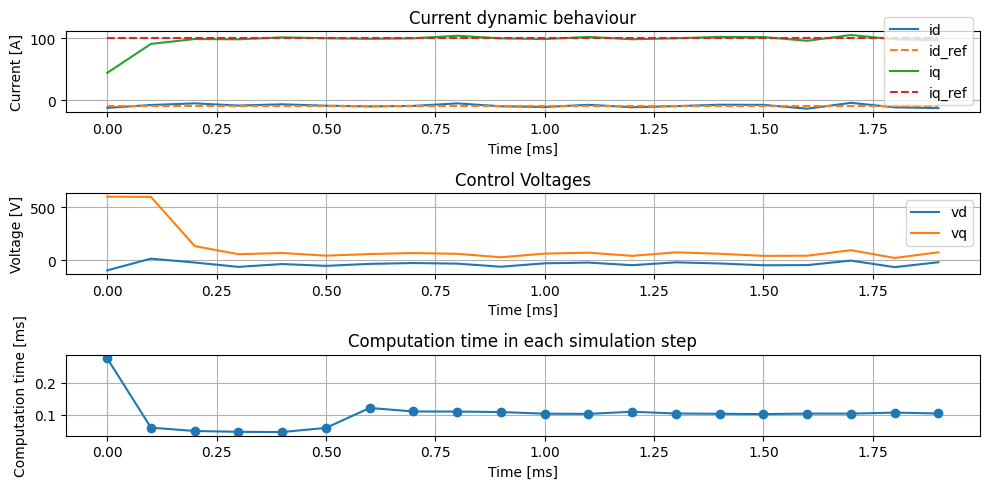

In [21]:
new_ddpg_with_noise.load_model("DDPG_noise_TL")
print("Transfer learning: DDPG pretrained on env, fine-tuned on noisy env")
_ = run_DDPG_controller_sim([env_noisy], new_ddpg_with_noise, index=["DDPG (TL) / noisy env"])

**Questions**
1. Compare the transfer-learning agent with the agent trained on the noisy environment from scratch. Which is better?
   Which needed less training?
2. When we load the clean weights, the replay buffer of the new agent is still empty, and `learning_starts` random steps are
   taken first. Is that a good idea when starting from a trained agent? What would you change?
3. Where could transfer learning help in practice? Think of going from simulation to a real motor.

---
### Summary
- **Actor**: maps states to continuous actions. Tanh plus scaling enforces the action limits.
- **Critic**: estimates $Q(s,a)$ and is trained with the Bellman equation.
- **Replay buffer**: breaks correlations and reuses data.
- **Target networks + soft updates**: stabilise the moving target.
- **Exploration noise**: needed because the Actor is deterministic. Its size matters.
- **Measurement noise** makes learning harder. Training with noise and transfer learning are two ways to deal with it.